# Questions

1) What does the guest satisfaction score look like overall? Look at the average, the lowest and highest values, and how the scores are spread out.

2) Do Room_Rate_INR and Meal_Spend_INR affect the satisfaction score? Check whether higher rates or higher meal spending go with higher or lower scores.

3) Does the score differ by Hotel_City, Room_Type, Booking_Channel and Customer_Type? Compare the average score across the groups in each of these columns.

4) Which bookings need attention? Label a booking “At Risk” if its Guest_Satisfaction_Score is below 5.5, then see how many there are and what they have in common.

# Business Problem

A regional hotel chain with properties in five Indian cities wants to understand what drives guest satisfaction. The revenue manager needs to know which booking and stay factors move the satisfaction score, and which bookings are at risk of unhappy guests, so the chain can improve service and protect repeat business.

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/raw/hotel_bookings_data.csv")

print(df.head())
print(df.shape)
print(df.info())
print(df.describe())
print(df.isnull().sum())
print(df.duplicated().sum())
print(df["Hotel_City"].value_counts())

       Lead_Time_Days  Stay_Nights  Num_Guests  Room_Rate_INR  Meal_Spend_INR  \
count      249.000000   255.000000  255.000000     255.000000       250.00000   
mean        29.180723     3.090196    2.568627    5001.568627      1250.88000   
std         20.985677     1.370277    1.174783    2168.928191       483.47141   
min          1.000000    -2.000000    1.000000    2000.000000         0.00000   
25%         14.000000     2.000000    2.000000    3450.000000       930.00000   
50%         25.000000     3.000000    2.000000    4300.000000      1280.00000   
75%         39.000000     4.000000    3.000000    6150.000000      1550.00000   
max        130.000000     8.000000    5.000000   13050.000000      2450.00000   

       Guest_Satisfaction_Score  
count                255.000000  
mean                   6.835686  
std                    1.333318  
min                    3.400000  
25%                    5.900000  
50%                    6.800000  
75%                    7.600000 

In [ ]:
print("Duplicates found:", df.duplicated().sum())
df = df.drop_duplicates()
print(f"Number of duplicates: {df.duplicated().sum()}\n")

df["Hotel_City"] = df["Hotel_City"].str.strip().str.title()
print(df["Hotel_City"].value_counts())

print("Bad Stay_Nights rows:", (df["Stay_Nights"] < 1).sum())
df.loc[df["Stay_Nights"] < 1, "Stay_Nights"] = np.nan

df["Stay_Nights"] = df["Stay_Nights"].fillna(df["Stay_Nights"].median())
df["Lead_Time_Days"] = df["Lead_Time_Days"].fillna(df["Lead_Time_Days"].median())
df["Meal_Spend_INR"] = df["Meal_Spend_INR"].fillna(df["Meal_Spend_INR"].median())

df["Customer_Type"] = df["Customer_Type"].fillna(df["Customer_Type"].mode()[0])
df["Booking_Channel"] = df["Booking_Channel"].fillna(df["Booking_Channel"].mode()[0])

print(df.isnull().sum())
print(df.describe())
print(df.shape)

df = df.reset_index(drop=True)
df.to_csv("../data/processed/hotel_bookings_clean.csv", index=False)

Number of duplicates: 0

Hotel_City
Mumbai       79
Bengaluru    57
Delhi        56
Goa          36
Jaipur       22
Name: count, dtype: int64


In [ ]:
df["Total_Room_Revenue"] = df["Room_Rate_INR"] * df["Stay_Nights"]

df["Risk_Flag"] = np.where(df["Guest_Satisfaction_Score"] < 5.5, "At Risk", "OK")

df["Lead_Time_Band"] = pd.cut(
    df["Lead_Time_Days"],
    bins=[-1, 7, 30, 90, 180],
    labels=["Last-minute", "Short", "Planned", "Early"]
)

print(df[["Total_Room_Revenue", "Risk_Flag", "Lead_Time_Band"]].head())
print(df["Risk_Flag"].value_counts())
print(df["Lead_Time_Band"].value_counts())

Matplotlib is building the font cache; this may take a moment.


count    255.000000
mean       6.835686
std        1.333318
min        3.400000
25%        5.900000
50%        6.800000
75%        7.600000
max       10.000000
Name: Guest_Satisfaction_Score, dtype: float64


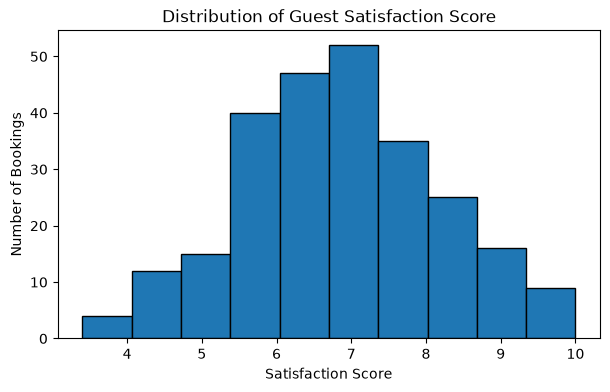

In [ ]:
import matplotlib.pyplot as plt

print(df["Guest_Satisfaction_Score"].describe())

df["Guest_Satisfaction_Score"].plot(kind="hist", bins=10)
plt.title("Guest Satisfaction Score")
plt.xlabel("Score")
plt.savefig("../images/q1_score_distribution.png")
plt.show()

In [ ]:
print(df["Room_Rate_INR"].corr(df["Guest_Satisfaction_Score"]))
print(df["Meal_Spend_INR"].corr(df["Guest_Satisfaction_Score"]))

df.plot(kind="scatter", x="Room_Rate_INR", y="Guest_Satisfaction_Score")
plt.title("Room Rate vs Score")
plt.savefig("../images/q2_rate_vs_score.png")
plt.show()

In [ ]:
print(df.groupby("Hotel_City")["Guest_Satisfaction_Score"].mean())
print(df.groupby("Room_Type")["Guest_Satisfaction_Score"].mean())
print(df.groupby("Booking_Channel")["Guest_Satisfaction_Score"].mean())
print(df.groupby("Customer_Type")["Guest_Satisfaction_Score"].mean())

df.groupby("Room_Type")["Guest_Satisfaction_Score"].mean().plot(kind="bar")
plt.title("Average Score by Room Type")
plt.ylabel("Average Score")
plt.savefig("../images/q3_score_by_room_type.png")
plt.show()

In [ ]:
print(df["Risk_Flag"].value_counts())

df["Risk_Flag"].value_counts().plot(kind="bar")
plt.title("At Risk vs OK Bookings")
plt.ylabel("Number of Bookings")
plt.savefig("../images/q4_at_risk_count.png")
plt.show()